# Project 

## Customer Segmentation data using unsupervied learning techniques

In [1]:
# importing liabraries 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

#### Data preprocessing 

In [3]:
df = pd.read_csv("D:/CODING/ML using Python/CompleteMachineLearningwithPython/Complete Machine Learning with Python/Practise set data file/Mall_Customers.csv",header=0)
df_backup = df.copy()

In [4]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [6]:
df.isna().sum() # there is no missing values in the dataset

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [7]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [8]:
df['Gender']

0        Male
1        Male
2      Female
3      Female
4      Female
        ...  
195    Female
196    Female
197      Male
198      Male
199      Male
Name: Gender, Length: 200, dtype: object

In [9]:
df['Gender'] = df['Gender'].map({'Male':1,'Female':0}) 

In [10]:
df.head() # coverting the gender column into numerical values

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40


In [11]:
# droping customerID column as it is not required for analysis
df = df.drop('CustomerID', axis=1)

In [12]:
df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


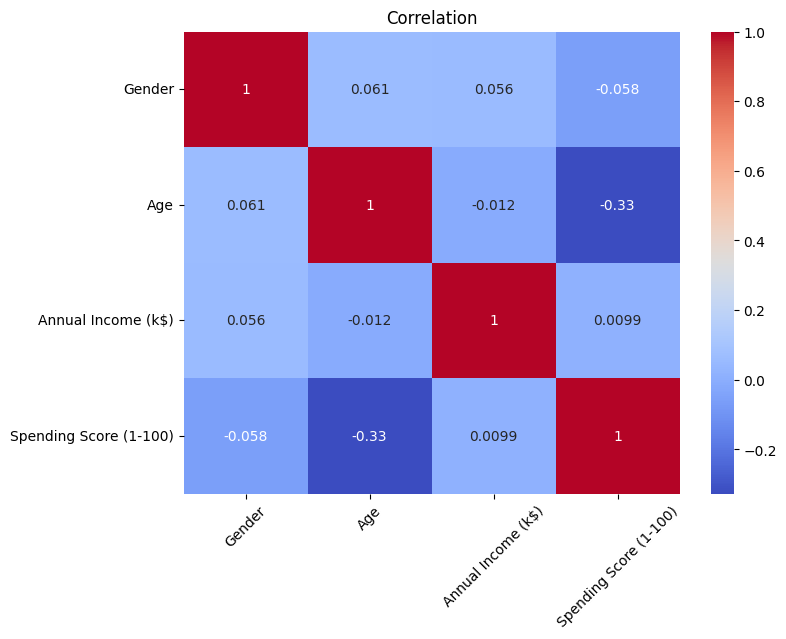

In [13]:
# correaltion of the numerical 
corr = df.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation")
plt.xticks(rotation=45)
plt.show()

*KMeans clusters*

In [14]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler 
from sklearn.metrics import silhouette_score 

In [15]:
# standardizing the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [16]:
n_clusters = range(2,13)
model = []
score = []
inertia = []
for i in n_clusters:
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(X_scaled)
    model.append(kmeans)
    inertia.append(kmeans.inertia_)
    score.append(silhouette_score(X_scaled, kmeans.labels_, metric='euclidean')) # this is the silhouette score for each value of k.

In [17]:
model 

[KMeans(n_clusters=2, random_state=42),
 KMeans(n_clusters=3, random_state=42),
 KMeans(n_clusters=4, random_state=42),
 KMeans(n_clusters=5, random_state=42),
 KMeans(n_clusters=6, random_state=42),
 KMeans(n_clusters=7, random_state=42),
 KMeans(random_state=42),
 KMeans(n_clusters=9, random_state=42),
 KMeans(n_clusters=10, random_state=42),
 KMeans(n_clusters=11, random_state=42),
 KMeans(n_clusters=12, random_state=42)]

In [18]:
score

[0.2776035125578272,
 0.2576199805135528,
 0.29010917402310876,
 0.27191023466188324,
 0.3347543475669217,
 0.3457397879257699,
 0.3727647594212929,
 0.3876146244442297,
 0.42076374869477745,
 0.42750694213514717,
 0.42570130766571246]

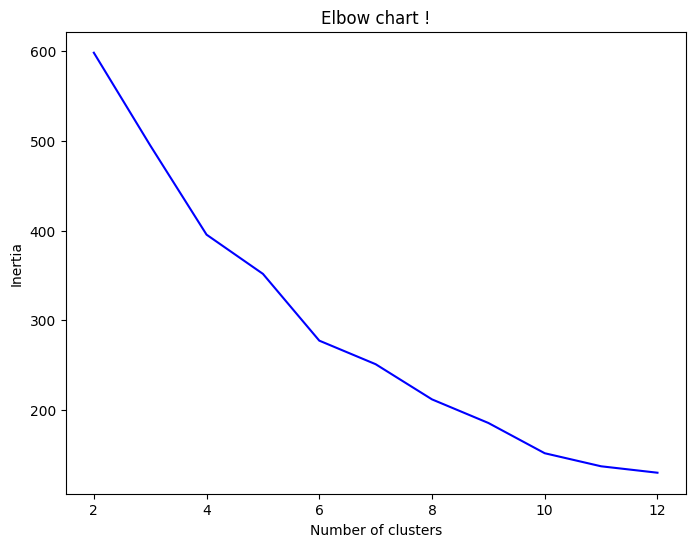

In [19]:
# visualizing the elbow chart to find the optimal number of clusters
plt.figure(figsize=(8,6))
sns.lineplot(x=n_clusters, y=inertia, color='blue')
#sns.lineplot(x=n_clusters, y=score, color='red')
plt.title("Elbow chart !")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.show()

*by above graph we can say that the optimal number of clusters is 6* 

In [ ]:
# model made by optimal number of clusters
kmeans = KMeans(n_clusters=6, random_state=42)
kmeans.fit(X_scaled)
labels = kmeans.labels_

In [21]:
labels # predicted values of clusters 

array([2, 2, 4, 4, 4, 4, 5, 4, 0, 4, 0, 4, 5, 4, 0, 2, 4, 2, 0, 4, 0, 2,
       5, 2, 5, 2, 5, 2, 5, 4, 0, 4, 0, 2, 5, 4, 5, 4, 5, 4, 5, 2, 0, 4,
       5, 4, 5, 4, 4, 4, 5, 2, 4, 0, 5, 0, 5, 0, 4, 0, 0, 2, 5, 5, 0, 2,
       5, 5, 2, 4, 0, 5, 5, 5, 0, 2, 5, 2, 4, 5, 0, 2, 0, 5, 4, 0, 5, 4,
       4, 5, 5, 2, 0, 5, 4, 2, 5, 4, 0, 2, 4, 5, 0, 2, 0, 4, 5, 0, 0, 0,
       0, 4, 5, 2, 4, 4, 5, 5, 5, 5, 2, 5, 3, 2, 4, 3, 1, 2, 0, 2, 1, 2,
       4, 3, 1, 3, 5, 2, 1, 3, 5, 2, 3, 3, 1, 2, 1, 3, 5, 2, 1, 2, 5, 3,
       5, 3, 1, 3, 1, 3, 5, 3, 1, 3, 1, 3, 1, 3, 5, 2, 1, 2, 1, 2, 5, 3,
       1, 2, 1, 2, 3, 3, 1, 3, 3, 2, 5, 2, 1, 3, 3, 3, 1, 3, 1, 3, 3, 3,
       1, 3], dtype=int32)

In [ ]:
print(pd.DataFrame({'Clusters':labels}).value_counts()) # number of data points in each clusters 

Clusters
5           47
2           39
4           36
3           29
0           28
1           21
Name: count, dtype: int64


In [22]:
group = df.groupby(labels).mean() # mean of each cluster

In [23]:
group.tail()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
1,0.904762,39.000000,88.333333,14.428571
2,1.000000,28.410256,58.230769,70.717949
3,0.068966,33.206897,91.034483,72.137931
4,0.000000,25.888889,41.277778,57.944444
5,0.000000,49.914894,54.255319,36.531915


<Figure size 1200x800 with 0 Axes>

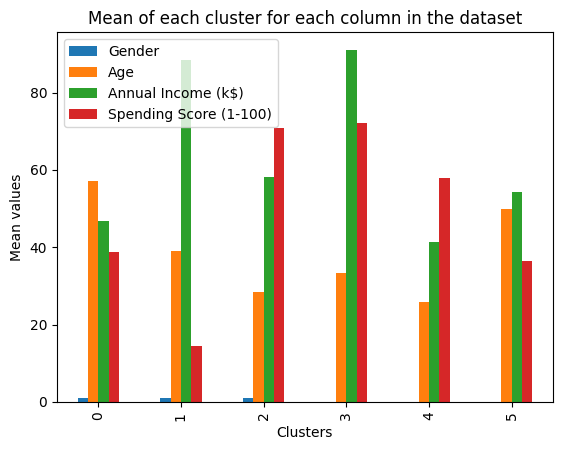

In [24]:
# this is barplot based on the mean of each cluster for each column in the dataset
plt.figure(figsize=(12,8))
group.plot(kind='bar')
plt.title("Mean of each cluster for each column in the dataset")
plt.xlabel("Clusters")
plt.ylabel("Mean values")
plt.show()

<Axes: xlabel='Annual Income (k$)', ylabel='Spending Score (1-100)'>

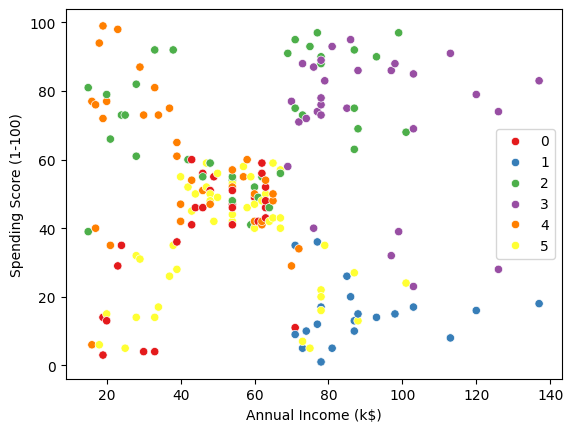

In [25]:
sns.scatterplot(x=df['Annual Income (k$)'], y=df['Spending Score (1-100)'], hue=labels, palette='Set1') 
# this is scatter plot based wihtout pca 

*PCA Principal Component Analysis*

In [26]:
from sklearn.decomposition import PCA

In [27]:
pca = PCA(n_components = 2, random_state=42)
x_pca = pca.fit(X_scaled).transform(X_scaled)
x_pca = pd.DataFrame(x_pca, columns=["PCA1", "PCA2"])
x_pca.head()

,PCA1,PCA2
0,-0.406383,-0.520714
1,-1.427673,-0.367310
2,0.050761,-1.894068
3,-1.694513,-1.631908
4,-0.313108,-1.810483


<Axes: xlabel='PCA1', ylabel='PCA2'>

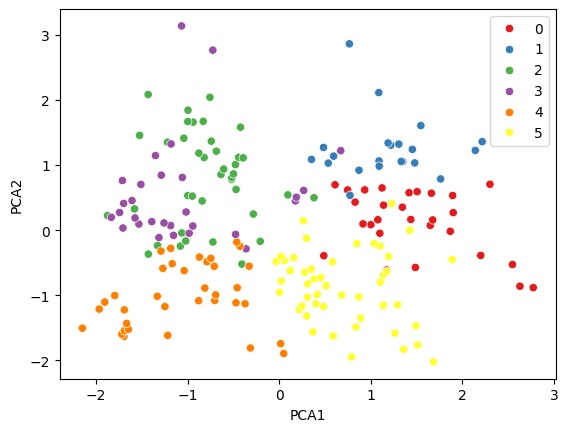

In [28]:
sns.scatterplot(x='PCA1', y='PCA2', hue=labels, data=x_pca, palette='Set1')

In [29]:
kmeans = KMeans(n_clusters=6, random_state=42)
kmeans.fit(x_pca)
kmeans.labels_ # predicted values of clusters based on pca
score = silhouette_score(x_pca, kmeans.labels_, metric='euclidean') # this is the silhouette score for each value of k based on pca.
print(score)

0.4032217492552414


*So After applying the PCA we can say that it is very easy to visualize the clusters in 2D space and we can see that the clusters are well separated and silhouette score is also good which is 0.40 approximately.*

In [30]:
data = df.copy()
data['Clusters'] = kmeans.labels_

In [31]:
data.head() # this is the final dataset with the predicted clusters 

,Gender,Age,Annual Income (k$),Spending Score (1-100),Clusters
0,1,19,15,39,1
1,1,21,15,81,4
2,0,20,16,6,1
3,0,23,16,77,2
4,0,31,17,40,1


<Axes: xlabel='Annual Income (k$)', ylabel='Age'>

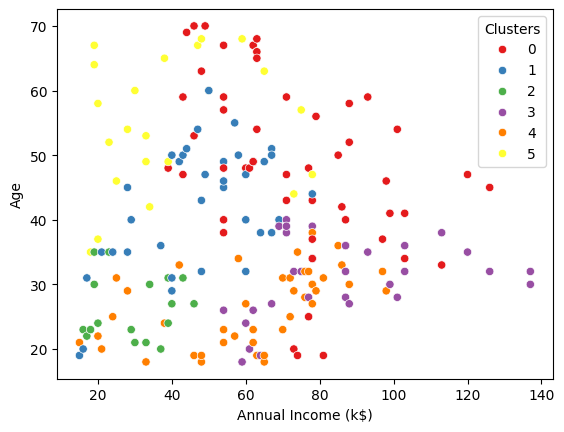

In [32]:
sns.scatterplot(x=data['Annual Income (k$)'], y=data['Age'], hue=data['Clusters'], palette='Set1')

<Axes: xlabel='Gender', ylabel='Annual Income (k$)'>

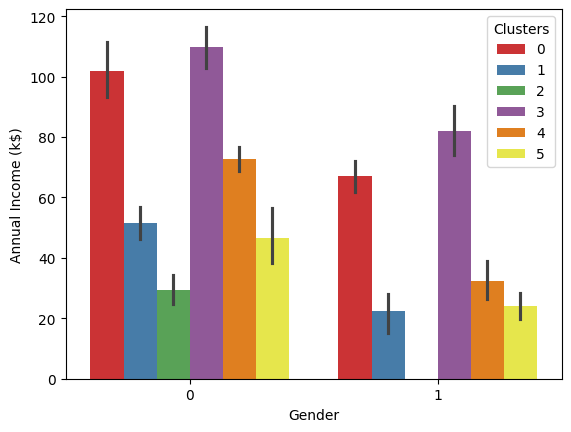

In [33]:
sns.barplot(x=data['Gender'], y=data['Annual Income (k$)'], data=data ,hue = data['Clusters'], palette='Set1')

In [34]:
# let's assign the category 
data['Category'] = data['Clusters'].map({0:'Sensible', 1:'Careful Savier', 2:'Impetous Spender', 3:'Top VIP Spenders', 4:'Careless Spender', 5:'Average Spender'})

In [35]:
data.head() # we assinged the category to each cluster based on the barplot we above build. 

,Gender,Age,Annual Income (k$),Spending Score (1-100),Clusters,Category
0,1,19,15,39,1,Careful Savier
1,1,21,15,81,4,Careless Spender
2,0,20,16,6,1,Careful Savier
3,0,23,16,77,2,Impetous Spender
4,0,31,17,40,1,Careful Savier
